In [12]:
import numpy as np
import matplotlib.pyplot as plt

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=BIGGER_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=BIGGER_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=MEDIUM_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [13]:
datasets = open("3d.txt").readlines()
datasets = [d.strip() for d in datasets]
ss_files = [f"data/{d}/ss.txt" for d in datasets]
    

In [14]:
def pairs_from_secondary(input_string: str) -> list[tuple[int, int]]:
    """
        Will give a list of pairs of indices that are paired in the secondary structure.
        (i,j): i < j is garanteed
    """
    open_par = ['(', '[', '{', '<', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J']
    close_par = [')', ']', '}', '>', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']

    stacks = {}  # Contains tuple with (is_open, stack)

    for open, close in zip(open_par, close_par):
        stacks[open] = (True, [])
        stacks[close] = (False, stacks[open][1])  # Points to the same stack

    result = []  # List to store pairs of matching indices

    for index, char in enumerate(input_string):
        if char in stacks:
            is_open, stack = stacks[char]
            if is_open:
                stack.append(index)
            else:
                open_index = stack.pop()
                result.append((open_index, index))

    assert (all([not bool(stack) for (_, stack) in stacks.values()]))

    return result

In [15]:
def collect(method):
    all_mask = []
    all_scores = []

    file = "reg0.5_mireg0.01_scoreoptdiff_corrAPC_with_null.npz"

    if method == "phylo_score_null":
        p_values = [np.load(f"data/{d}/{file}")['null_p_values'] for d in datasets]
    elif method == "phylo_score_fast":
        p_values = [np.load(f"data/{d}/{file}")['fast_p_values'] for d in datasets]
    elif method == "phylo_score_pure":
        scores = [np.load(f"data/{d}/{file}")['corrected_scores'] for d in datasets]
        p_values = [-s for s in scores]
    elif method == "rscape":
        score_files = [f"data/{d}/rscape_GTp.npz" for d in datasets]
        p_values = [np.load(f)['p_values'] for f in score_files]
    elif method == "rscape_score":
        score_files = [f"data/{d}/rscape_GTp.npz" for d in datasets]
        p_values = [-np.load(f)['scores'] for f in score_files]
    for p_val, ss in zip(p_values, ss_files):
        ss = open(ss, 'r').read().strip()
        true_pairs = pairs_from_secondary(ss)
        all_pairs = np.triu_indices(len(ss), k = 1)

        mask = [p in true_pairs for p in zip(all_pairs[0], all_pairs[1])]
        
        all_mask.extend(mask)
        all_scores.extend(-p_val)
    return np.array(all_mask), np.array(all_scores)

In [16]:
from sklearn.metrics import precision_recall_curve, average_precision_score

def plot_pr_curves(output: str, mask, scores : list, labels):
    plt.figure(figsize=(10, 10))
    plt.xlim(0, 1)
    plt.ylim(0, 1)
    for s, l in zip(scores, labels):
        precision, recall, _ = precision_recall_curve(mask, s)
        ap = average_precision_score(mask, s)
        plt.plot(recall, precision, label=f"{l} (AP={ap:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid()
    plt.savefig(output)
    plt.show()

In [17]:
mask, rscape_scores = collect("rscape")
_, pure_scores = collect("phylo_score_pure")
_, phylo_score_scores = collect("phylo_score_fast")
_, phylo_score_null_scores = collect("phylo_score_null")
_, rscape_score_scores = collect("rscape_score")

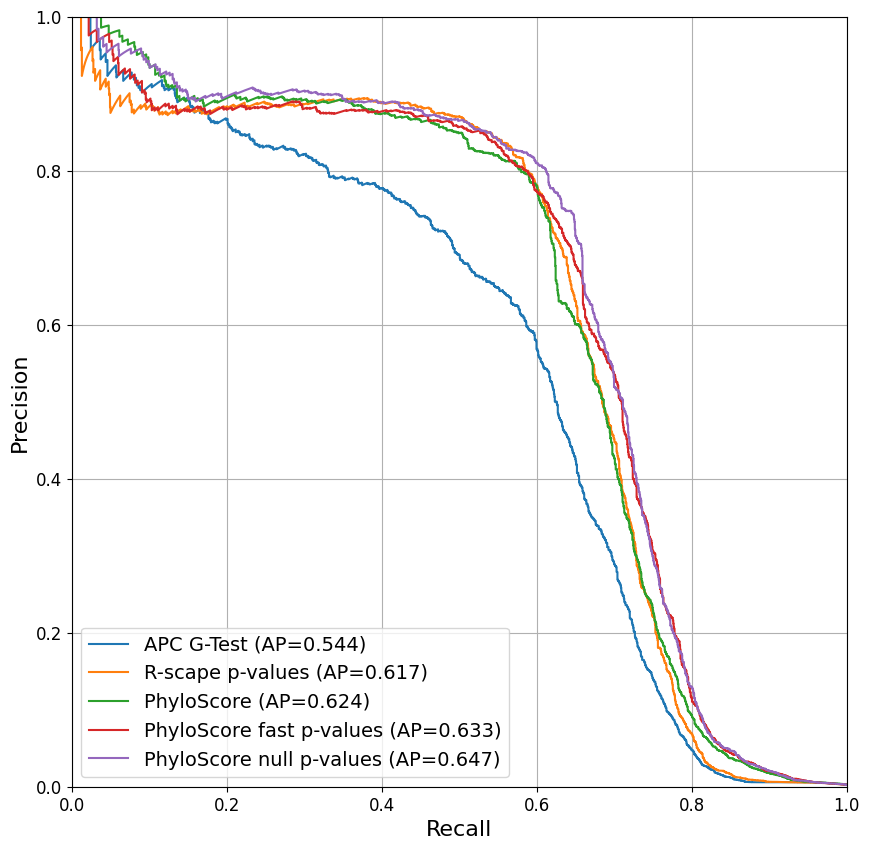

In [19]:
plot_pr_curves("joint.pdf", mask, [rscape_score_scores, rscape_scores, pure_scores, phylo_score_scores, phylo_score_null_scores], labels=["APC G-Test", "R-scape p-values", "PhyloScore", "PhyloScore fast p-values", "PhyloScore null p-values"])